# MRV emission factor validation

**What this notebook does.** It compares the ocean emission factor used in the case analyses (UK DESNZ, 0.020 kg CO₂e per tonne-km for container ships) against observed fuel consumption and CO₂ emissions per ship from the EMSA THETIS-MRV, for ships that also appear in the Climate TRACE container-ship voyage data.

**Why it matters.** The case analyses multiply distance × factor for every sea leg. If the assumed factor is far from the observed distribution, the lane comparisons are misstated. MRV reports annual totals per ship, not per voyage, so this is a population check, not a per-leg calibration.

**To run:** set `ANALYST_DATABASE_URL` in `analysis/.env`, then run all cells. It reads; it never writes to the database.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from shockt_engine import load_leg_factors, select_factors

from shockt_analysis import core
from shockt_analysis.settings import get_settings

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_float_precision(4)

NM_TO_KM = 1.852

In [2]:
with core.connect(get_settings()) as conn:
    mrv = core.ship_fuel_intensities(conn)
    factor_rows = core.factors(conn)
    loads = core.current_loads(conn, ["thetis_mrv", "climatetrace_voyages",
                                      "uk_ghg_conversion_factors"])

leg_factors = select_factors(factor_rows, load_leg_factors())
assumed_ocean = leg_factors["ocean"]
print(f"Assumed ocean factor: {assumed_ocean.variant}")
print(f"  {assumed_ocean.wtw_kg_co2e_per_tkm} kg CO2e per tonne-km ({assumed_ocean.source})")
print(f"\nMRV rows: {mrv.height:,}")
loads

Assumed ocean factor: Cargo ship / Container ship / Average
  0.01977 kg CO2e per tonne-km (uk_desnz)

MRV rows: 12,829


dataset,partitions,latest_load,code_versions
str,i64,str,str
"""climatetrace_voyages""",5,"""2026-10-12 22:52:15.201059+00""","""20b5845"""
"""thetis_mrv""",1,"""2026-10-23 21:53:59.104058+00""","""9ed641f-dirty"""
"""uk_ghg_conversion_factors""",1,"""2026-10-12 22:52:36.02174+00""","""20b5845"""


## 2. Population overview

How many MRV ships match the voyage data, by ship type.

In [3]:
overview = (
    mrv.group_by("ship_type")
    .agg(
        pl.len().alias("total"),
        pl.col("in_voyage_data").sum().alias("matched"),
    )
    .with_columns((pl.col("matched") / pl.col("total") * 100).round(1).alias("pct"))
    .sort("total", descending=True)
)
print(f"Total MRV ships: {mrv.height:,}")
print(f"Matched to voyage data: {mrv.filter(pl.col('in_voyage_data')).height:,} "
      f"({mrv.filter(pl.col('in_voyage_data')).height / mrv.height:.1%})")
overview.head(12)

Total MRV ships: 12,829
Matched to voyage data: 587 (4.6%)


ship_type,total,matched,pct
str,u32,u32,f64
"""Bulk carrier""",3796,0,0.0000
"""Oil tanker""",1929,0,0.0000
"""Container ship""",1928,587,30.4000
"""Chemical tanker""",1354,0,0.0000
"""General cargo ship""",1231,0,0.0000
"""Vehicle carrier""",461,0,0.0000
"""Ro-pax ship""",404,0,0.0000
"""LNG carrier""",371,0,0.0000
"""Other ship types""",367,0,0.0000


## 3. CO₂ intensity of matched container ships

MRV reports `co2_per_distance_kg_nm` (kg CO₂ per nautical mile for the whole ship) and `co2_per_transport_work_mass` (g CO₂ per metric tonne · nautical mile). The second is the per-tonne intensity we need. Convert from g per (t·nm) to kg per (t·km) to compare with the assumed factor.

Note: MRV reports CO₂ only, not CO₂e; the UK DESNZ factor is CO₂e (includes upstream well-to-tank). The comparison is therefore conservative: MRV's tank-to-wake CO₂ should be lower than the WTW CO₂e factor.

In [4]:
containers = mrv.filter(
    (pl.col("ship_type") == "Container ship")
    & pl.col("in_voyage_data")
    & pl.col("co2_per_transport_work_mass").is_not_null()
    & (pl.col("co2_per_transport_work_mass") > 0)
).with_columns(
    (pl.col("co2_per_transport_work_mass") / 1000 / NM_TO_KM).alias("kg_co2_per_tkm")
)
print(f"Container ships with voyage match and transport-work intensity: {containers.height}")

Container ships with voyage match and transport-work intensity: 585


In [5]:
intensity = containers["kg_co2_per_tkm"]
pcts = [5, 10, 25, 50, 75, 90, 95]
quantiles = intensity.quantile([p / 100 for p in pcts])
stats = pl.DataFrame({
    "statistic": [f"p{p}" for p in pcts] + ["mean", "std", "n"],
    "kg_co2_per_tkm": [
        *[intensity.quantile(p / 100) for p in pcts],
        intensity.mean(),
        intensity.std(),
        float(intensity.len()),
    ],
})
print(f"Assumed ocean factor (WTW CO2e): {assumed_ocean.wtw_kg_co2e_per_tkm} kg/tkm")
print(f"MRV median (TTW CO2 only):       {intensity.median():.4f} kg/tkm")
print(f"MRV mean:                         {intensity.mean():.4f} kg/tkm")
stats

Assumed ocean factor (WTW CO2e): 0.01977 kg/tkm
MRV median (TTW CO2 only):       0.0075 kg/tkm
MRV mean:                         0.0124 kg/tkm


statistic,kg_co2_per_tkm
str,f64
"""p5""",0.0039
"""p10""",0.0045
"""p25""",0.0057
"""p50""",0.0075
"""p75""",0.0105
"""p90""",0.0142
"""p95""",0.0175
"""mean""",0.0124
"""std""",0.0745


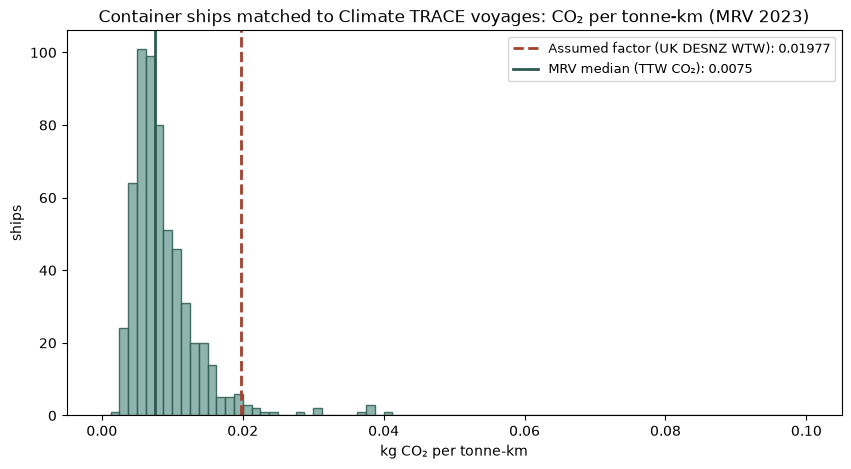

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
values = intensity.to_numpy()
ax.hist(values, bins=80, range=(0, 0.10), color="#7ca8a0", edgecolor="#2d5b4f", alpha=0.85)
ax.axvline(assumed_ocean.wtw_kg_co2e_per_tkm, color="#a2412d", ls="--", lw=2,
           label=f"Assumed factor (UK DESNZ WTW): {assumed_ocean.wtw_kg_co2e_per_tkm}")
ax.axvline(intensity.median(), color="#2d5b4f", ls="-", lw=2,
           label=f"MRV median (TTW CO₂): {intensity.median():.4f}")
ax.set_xlabel("kg CO₂ per tonne-km")
ax.set_ylabel("ships")
ax.set_title("Container ships matched to Climate TRACE voyages: CO₂ per tonne-km (MRV 2023)")
ax.legend(fontsize=9)
plt.show()

## 4. Intensity by ship type

The same distribution for every ship type with at least 20 matched ships, to check whether the assumed factor is specific to container ships or broadly representative.

In [7]:
all_matched = mrv.filter(
    pl.col("in_voyage_data")
    & pl.col("co2_per_transport_work_mass").is_not_null()
    & (pl.col("co2_per_transport_work_mass") > 0)
).with_columns(
    (pl.col("co2_per_transport_work_mass") / 1000 / NM_TO_KM).alias("kg_co2_per_tkm")
)

by_type = (
    all_matched.group_by("ship_type")
    .agg(
        pl.len().alias("n"),
        pl.col("kg_co2_per_tkm").median().alias("median"),
        pl.col("kg_co2_per_tkm").mean().alias("mean"),
        pl.col("kg_co2_per_tkm").quantile(0.25).alias("p25"),
        pl.col("kg_co2_per_tkm").quantile(0.75).alias("p75"),
    )
    .filter(pl.col("n") >= 20)
    .sort("median")
)
by_type

ship_type,n,median,mean,p25,p75
str,u32,f64,f64,f64,f64
"""Container ship""",585,0.0075,0.0124,0.0057,0.0105


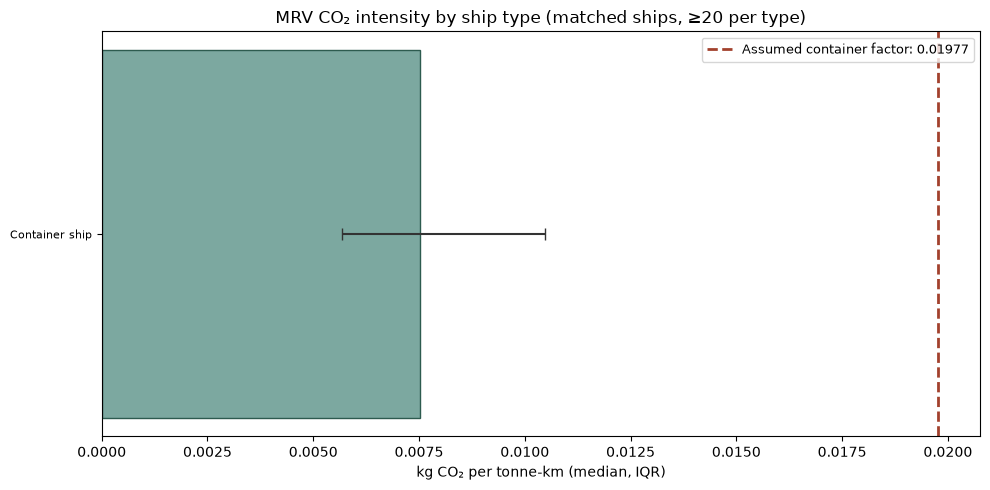

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
types = by_type["ship_type"].to_list()
medians = by_type["median"].to_list()
p25 = by_type["p25"].to_list()
p75 = by_type["p75"].to_list()
y = range(len(types))
ax.barh(list(y), medians, color="#7ca8a0", edgecolor="#2d5b4f", height=0.6)
ax.errorbar(medians, list(y),
            xerr=[[m - lo for m, lo in zip(medians, p25)],
                  [hi - m for m, hi in zip(medians, p75)]],
            fmt="none", ecolor="#333", capsize=4)
ax.axvline(assumed_ocean.wtw_kg_co2e_per_tkm, color="#a2412d", ls="--", lw=2,
           label=f"Assumed container factor: {assumed_ocean.wtw_kg_co2e_per_tkm}")
ax.set_yticks(list(y), types, fontsize=8)
ax.set_xlabel("kg CO₂ per tonne-km (median, IQR)")
ax.set_title("MRV CO₂ intensity by ship type (matched ships, ≥20 per type)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 5. Fuel consumption vs CO₂

A sanity check: the relationship between total fuel consumption and total CO₂ should be nearly linear (the emission factor per tonne of fuel is roughly constant for HFO/VLSFO). Outliers suggest data quality issues.

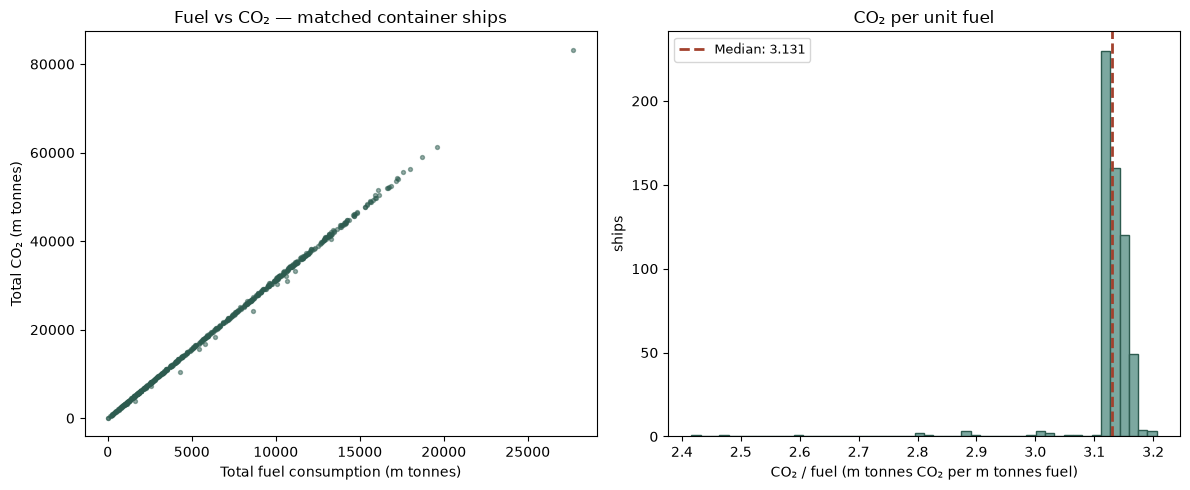

CO₂ per fuel — median: 3.131, IQR: 3.120–3.151
Expected for HFO: ~3.114; for VLSFO: ~3.151 (IMO fourth GHG study, Table 13)


In [9]:
valid = containers.filter(
    pl.col("total_fuel_consumption_mt").is_not_null()
    & pl.col("total_co2_mt").is_not_null()
    & (pl.col("total_fuel_consumption_mt") > 0)
).with_columns(
    (pl.col("total_co2_mt") / pl.col("total_fuel_consumption_mt")).alias("co2_per_fuel")
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.scatter(valid["total_fuel_consumption_mt"].to_numpy(),
            valid["total_co2_mt"].to_numpy(),
            s=8, alpha=0.5, color="#2d5b4f")
ax1.set_xlabel("Total fuel consumption (m tonnes)")
ax1.set_ylabel("Total CO₂ (m tonnes)")
ax1.set_title("Fuel vs CO₂ — matched container ships")

ratio = valid["co2_per_fuel"]
ax2.hist(ratio.to_numpy(), bins=50, color="#7ca8a0", edgecolor="#2d5b4f")
ax2.axvline(ratio.median(), color="#a2412d", ls="--", lw=2,
            label=f"Median: {ratio.median():.3f}")
ax2.set_xlabel("CO₂ / fuel (m tonnes CO₂ per m tonnes fuel)")
ax2.set_ylabel("ships")
ax2.set_title("CO₂ per unit fuel")
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"CO₂ per fuel — median: {ratio.median():.3f}, IQR: {ratio.quantile(0.25):.3f}–{ratio.quantile(0.75):.3f}")
print(f"Expected for HFO: ~3.114; for VLSFO: ~3.151 (IMO fourth GHG study, Table 13)")

## 6. Findings

All values computed from the cells above.

In [10]:
pct_below = (intensity < assumed_ocean.wtw_kg_co2e_per_tkm).mean() * 100
container_row = by_type.filter(pl.col("ship_type") == "Container ship")

findings = [
    f"{containers.height} container ships have both MRV fuel data and Climate TRACE voyages.",
    f"Their CO₂ per tonne-km (TTW, MRV) has a median of {intensity.median():.4f} and a mean of "
    f"{intensity.mean():.4f} kg CO₂/tkm, against the assumed WTW factor of "
    f"{assumed_ocean.wtw_kg_co2e_per_tkm}.",
    f"{pct_below:.0f}% of matched container ships have a TTW intensity below the assumed WTW "
    f"factor; the remainder are above it.",
    f"The IQR is {intensity.quantile(0.25):.4f}–{intensity.quantile(0.75):.4f} kg CO₂/tkm, "
    f"a roughly {(intensity.quantile(0.75) / intensity.quantile(0.25) - 1):.0%} spread from "
    f"the more efficient quarter to the less efficient quarter.",
    f"CO₂ per unit fuel is tightly clustered around {ratio.median():.3f}, consistent with "
    f"HFO/VLSFO, so the intensity spread comes from operational efficiency, not fuel type.",
]
for f in findings:
    print("-", f)

- 585 container ships have both MRV fuel data and Climate TRACE voyages.
- Their CO₂ per tonne-km (TTW, MRV) has a median of 0.0075 and a mean of 0.0124 kg CO₂/tkm, against the assumed WTW factor of 0.01977.
- 97% of matched container ships have a TTW intensity below the assumed WTW factor; the remainder are above it.
- The IQR is 0.0057–0.0105 kg CO₂/tkm, a roughly 84% spread from the more efficient quarter to the less efficient quarter.
- CO₂ per unit fuel is tightly clustered around 3.131, consistent with HFO/VLSFO, so the intensity spread comes from operational efficiency, not fuel type.
